# Case 2 - Recurrent networks for an explainable price-spike early warning

Master - Neural Networks and Deep Learning (NN) - Prof. Daniel Traian Pele

Bucharest University of Economic Studies - Romanian Academy, Institute for Economic Forecasting

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C2_spike_recurrent')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "en"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Paper.** Andrei, A.-V., Pele, D.-T., Cramer, A.-A., Amza, A. & Diaconu, D. (2026). Explainable AI-based early warning system for electricity
price spikes: Evidence from the Romanian market. *Proceedings of the International Conference on Business Excellence (PICBE)*, 20(1), 4820-4836.
doi:10.2478/picbe-2026-0352. Related work of the group: Andrei, Pele & Cramer (2026), multi-horizon explainability in energy price forecasting, PICBE 20(1), 104-117,
doi:10.2478/picbe-2026-0014.

**What we do here.** (1) Define a spike as an hourly day-ahead price above the 90th percentile of the training period. (2) Build the paper's model,
a gradient-boosted tree classifier (XGBoost, eXtreme Gradient Boosting) explained with SHAP (SHapley Additive exPlanations), and its transparent
indicator warning score. (3) Add the Lecture 5 model: a recurrent neural network (LSTM, Long Short-Term Memory, and GRU, Gated Recurrent Unit) that reads the last
14 days of hourly history and outputs the 24 spike probabilities of the next day; five seeds per network. (4) Explain the network with integrated gradients over the
time steps of its input (Lecture 11): which hours of the past drive an alert? (5) Turn the probability into a decision with a cost-loss rule.

**Information set.** Bids for day d are due at 12:00 CET on day d-1. At that moment the prices of day d-1 are known (that auction cleared on d-2),
but load and generation are metered only up to day d-2. Our data contain no day-ahead forecasts of load, solar and wind, so every model uses the realised
values of day d-2 in their place. Training 2023-2024, validation January-June 2025, test July 2025 - October 2026.

## 1. Data on a delivery-day grid and the spike definition

train     :  17542 hours, spike share 10.0 %
validation:   4343 hours, spike share 14.2 %
test      :  11711 hours, spike share 23.1 %
spike threshold (P90 of training prices): 163.43 EUR/MWh (paper: P90 = 149.99 EUR/MWh in 2024)


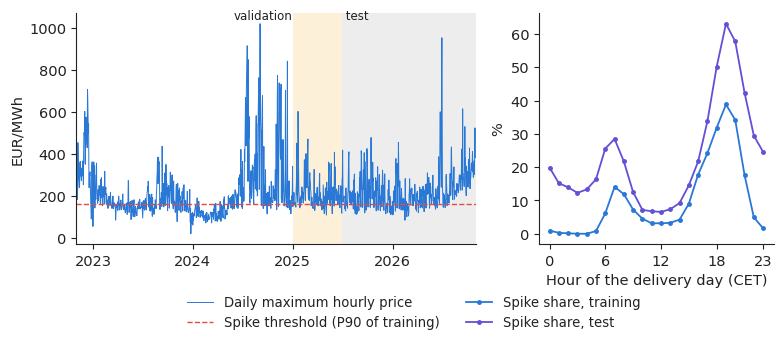

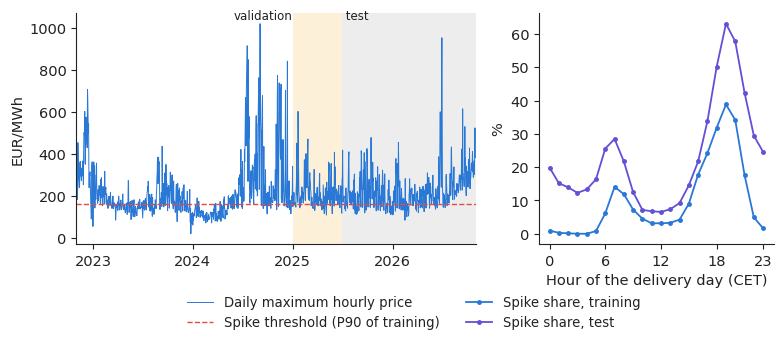

In [3]:
os.environ["OMP_NUM_THREADS"] = "1"          # PyTorch and XGBoost in the same process: one OpenMP thread each
import torch                                  # torch before sklearn / shap
torch.set_num_threads(4)
p = cu.prices_hourly("Europe/Brussels")["RO"]; g = cu.load_generation_ro_hourly("Europe/Brussels")
raw = pd.concat({"price": p, "load": g["load"], "solar": g["solar"], "wind": g["wind_onshore"], "hydro": g["hydro_water_reservoir"],
                 "gas": g["gas"], "net_import": g["cross_border_electricity_trading"]}, axis=1).loc["2022-11-01":"2026-10-31"]
# grid of CET delivery days x 24 hours: on the 25-hour day of October the repeated hour is averaged, on the 23-hour day of March
# the missing hour stays missing (it has no label and is never scored)
day = raw.index.tz_localize(None).normalize(); hr = raw.index.hour
full = pd.MultiIndex.from_product([pd.date_range(day.min(), day.max(), freq="D"), range(24)], names=["day", "hour"])
H = raw.groupby([day, hr]).mean().reindex(full)
H["resid_load"] = H.load - H.solar - H.wind                         # residual load (paper eq. 1, with forecasts)
TRAIN, VAL, TEST = ("2023-01-01", "2024-12-31"), ("2025-01-01", "2025-06-30"), ("2025-07-01", "2026-10-31")
D = H.index.get_level_values("day")
per = lambda a, b: (D >= pd.Timestamp(a)) & (D <= pd.Timestamp(b))
itr, iva, ite = per(*TRAIN), per(*VAL), per(*TEST)
thr = H.loc[itr, "price"].quantile(0.90)                           # P90 of training prices only
H["spike"] = np.where(H.price.isna(), np.nan, (H.price > thr).astype(float))
for nm, m_ in [("train", itr), ("validation", iva), ("test", ite)]:
    print(f"{nm:10s}: {int(H.loc[m_, 'spike'].notna().sum()):6d} hours, spike share {100 * H.loc[m_, 'spike'].mean():.1f} %")
print("spike threshold (P90 of training prices): %.2f EUR/MWh (paper: P90 = 149.99 EUR/MWh in 2024)" % thr)
share_h = pd.DataFrame({k: H.loc[m_].groupby(level="hour").spike.mean() * 100 for k, m_ in [("train", itr), ("test", ite)]})
def fig_data(lang):
    fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0), gridspec_kw={"width_ratios": [1.7, 1]})
    a = axes[0]
    d = H.price.groupby(level="day").max()
    a.plot(d.index, d, color=cu.PAL["RO"], lw=0.7, label=cu.T(lang, "Daily maximum hourly price", "Prețul orar maxim al zilei"))
    a.axhline(thr, color=cu.EVENT, ls="--", lw=1, label=cu.T(lang, "Spike threshold (P90 of training)", "Pragul de vîrf (P90 din antrenare)"))
    for (x0, x1), c in [(VAL, cu.PAL["BG"]), (TEST, cu.MUTED)]:
        a.axvspan(pd.Timestamp(x0), pd.Timestamp(x1), color=c, alpha=0.15, lw=0)
    a.text(pd.Timestamp(VAL[0]), d.max() * 1.02, cu.T(lang, "validation", "validare"), fontsize=8.5, ha="right")
    a.text(pd.Timestamp(TEST[0]), d.max() * 1.02, " test", fontsize=8.5)
    a.set_xlim(d.index.min(), d.index.max())
    a.set_ylabel("EUR/MWh")
    import matplotlib.dates as mdates
    a.xaxis.set_major_locator(mdates.YearLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    b = axes[1]
    b.plot(share_h.index, share_h["train"], color=cu.PAL["RO"], marker="o", ms=2.5, label=cu.T(lang, "Spike share, training", "Ponderea vîrfurilor, antrenare"))
    b.plot(share_h.index, share_h["test"], color=cu.PAL["c7"], marker="o", ms=2.5, label=cu.T(lang, "Spike share, test", "Ponderea vîrfurilor, test"))
    b.set_xlabel(cu.T(lang, "Hour of the delivery day (CET)", "Ora zilei de livrare (CET)")); b.set_ylabel("%")
    b.set_xticks([0, 6, 12, 18, 23])
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_data, "f1_spikes")

In [4]:
# Tabular features for the paper's model (one row = one delivery hour). Shifts are on the regular 24-hour grid, so shift(24) is exactly
# the same hour of the previous delivery day. Prices: day d-1 and earlier; load and generation: day d-2 and earlier.
P = H.price
X = pd.DataFrame(index=H.index)
for L in [24, 48, 72, 168, 336]:
    X[f"price_lag{L}"] = P.shift(L)
roll = P.shift(24).rolling(168, min_periods=150)
X["price_dev_7d"], X["price_vol_7d"] = P.shift(24) - roll.mean(), roll.std()
X["max_yday"] = P.groupby(level="day").transform("max").shift(24)          # daily maximum of day d-1
for c in ["load", "solar", "wind", "resid_load", "hydro", "gas", "net_import"]:
    X[c + "_d2"] = H[c].shift(48)
X["ren_share_d2"] = (H.solar + H.wind).shift(48) / H.load.shift(48)
X["balance_d2"] = (H.hydro + H.gas - H.load).shift(48)
X["hour"] = H.index.get_level_values("hour"); X["dow"] = D.dayofweek; X["month"] = D.month
y = H.spike
lab = y.notna() & X.price_lag24.notna()
print(X.shape, "features:", list(X.columns))

(35064, 20) features: ['price_lag24', 'price_lag48', 'price_lag72', 'price_lag168', 'price_lag336', 'price_dev_7d', 'price_vol_7d', 'max_yday', 'load_d2', 'solar_d2', 'wind_d2', 'resid_load_d2', 'hydro_d2', 'gas_d2', 'net_import_d2', 'ren_share_d2', 'balance_d2', 'hour', 'dow', 'month']


## 2. The paper's model: XGBoost with SHAP, and the indicator warning score

In [5]:
import xgboost as xgb
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, precision_recall_curve
grid = np.linspace(0.05, 0.9, 35)
def thr_val(s_val, y_val):
    """alert threshold chosen on the VALIDATION period by maximising F1 (as the paper calibrates its warning threshold)"""
    return grid[np.argmax([f1_score(y_val, s_val > c) for c in grid])]
def scores(y_true, alert, score):
    return {"Precision": precision_score(y_true, alert), "Recall": recall_score(y_true, alert), "F1": f1_score(y_true, alert),
            "PR-AUC": average_precision_score(y_true, score), "AUC": roc_auc_score(y_true, score)}
mtr, mva, mte = lab & itr, lab & iva, lab & ite
SEEDS = [0, 1, 2, 3, 4]
xgb_prob, xgb_runs = {}, []
for s in SEEDS:
    clf_s = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                              random_state=s, n_jobs=4, eval_metric="logloss").fit(X[mtr], y[mtr])
    pr = pd.Series(clf_s.predict_proba(X)[:, 1], index=X.index)
    c = thr_val(pr[mva], y[mva]); xgb_prob[s] = pr
    xgb_runs.append(scores(y[mte], pr[mte] > c, pr[mte]))
    if s == 0:
        clf = clf_s
xgb_runs = pd.DataFrame(xgb_runs, index=SEEDS)
print("XGBoost, 5 seeds (test):"); print(xgb_runs.round(3))

XGBoost, 5 seeds (test):
   Precision  Recall     F1  PR-AUC    AUC
0      0.818   0.542  0.652   0.813  0.946
1      0.815   0.550  0.657   0.809  0.945
2      0.816   0.557  0.662   0.811  0.945
3      0.810   0.503  0.621   0.797  0.942
4      0.818   0.571  0.672   0.811  0.945


price_lag24     1.123
dow             0.843
price_lag168    0.805
price_lag72     0.452
solar_d2        0.370
price_lag48     0.338
max_yday        0.299
price_lag336    0.278
hour            0.266
load_d2         0.241
dtype: float32


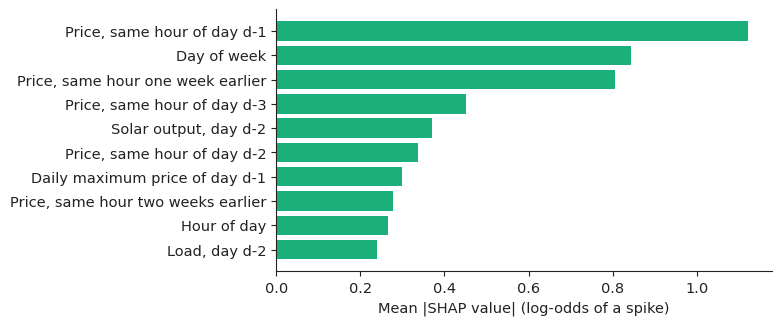

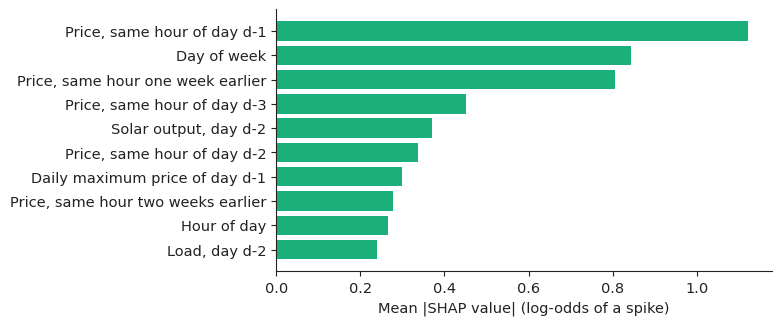

In [6]:
import shap
expl = shap.TreeExplainer(clf)
Xs = X[mte].sample(3000, random_state=0)
sv = expl.shap_values(Xs)
imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(3))
NM = {"price_lag24": ("Price, same hour of day d-1", "Prețul, aceeași oră din ziua d-1"), "price_lag48": ("Price, same hour of day d-2", "Prețul, aceeași oră din ziua d-2"),
      "price_lag72": ("Price, same hour of day d-3", "Prețul, aceeași oră din ziua d-3"), "price_lag168": ("Price, same hour one week earlier", "Prețul, aceeași oră cu o săptămînă înainte"),
      "price_lag336": ("Price, same hour two weeks earlier", "Prețul, aceeași oră cu două săptămîni înainte"),
      "price_dev_7d": ("Price deviation from its 7-day mean", "Abaterea prețului de la media pe 7 zile"), "price_vol_7d": ("7-day price volatility", "Volatilitatea prețului pe 7 zile"),
      "max_yday": ("Daily maximum price of day d-1", "Prețul maxim al zilei d-1"), "load_d2": ("Load, day d-2", "Consumul, ziua d-2"),
      "solar_d2": ("Solar output, day d-2", "Producția solară, ziua d-2"), "wind_d2": ("Wind output, day d-2", "Producția eoliană, ziua d-2"),
      "resid_load_d2": ("Residual load, day d-2", "Consumul rezidual, ziua d-2"), "hydro_d2": ("Hydro reservoir output, day d-2", "Producția hidro din lacuri, ziua d-2"),
      "gas_d2": ("Gas-fired output, day d-2", "Producția pe gaze, ziua d-2"), "net_import_d2": ("Net imports, day d-2", "Importurile nete, ziua d-2"),
      "ren_share_d2": ("Solar and wind share, day d-2", "Ponderea solarului și eolianului, ziua d-2"), "balance_d2": ("Hydro + gas minus load, day d-2", "Hidro + gaze minus consum, ziua d-2"),
      "hour": ("Hour of day", "Ora din zi"), "dow": ("Day of week", "Ziua săptămînii"), "month": ("Month", "Luna")}
def fig_shap(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    top = imp.head(10)[::-1]
    ax.barh([cu.T(lang, *NM.get(k, (k, k))) for k in top.index], top.values, color=cu.PAL["HU"])
    ax.set_xlabel(cu.T(lang, "Mean |SHAP value| (log-odds of a spike)", "Media |valorii SHAP| (logaritmul cotei de șansă a unui vîrf)"))
    cu.comma_axis(ax, lang, "x")
    return fig
cu.save_both(fig_shap, "f4_shap_xgboost")

In [7]:
# Indicator warning score (paper, Sec. 3): each indicator raises a flag above its threshold theta_m (chosen on TRAINING by F1, percentiles 50-95);
# W_t = sum_m w_m flag_m,t with w_m proportional to the indicator's F1; the alert threshold W* is chosen on VALIDATION.
IND = {"resid_load_d2": +1, "price_lag24": +1, "max_yday": +1, "price_dev_7d": +1, "price_vol_7d": +1, "load_d2": +1, "ren_share_d2": -1, "balance_d2": -1}
th, f1w = {}, {}
for k, sgn in IND.items():
    v = sgn * X.loc[mtr, k]
    cands = np.nanpercentile(v, np.arange(50, 96, 1))
    f1s = [f1_score(y[mtr], v >= c) for c in cands]
    th[k] = cands[int(np.argmax(f1s))]; f1w[k] = max(f1s)
w = pd.Series(f1w) / sum(f1w.values())
W = pd.DataFrame({k: (IND[k] * X[k] >= th[k]).astype(int) for k in IND}) @ w
gridW = np.linspace(0.05, 0.95, 37)
W_star = gridW[np.argmax([f1_score(y[mva], W[mva] >= c) for c in gridW])]
print("indicator F1 (training):", {k: round(v, 3) for k, v in f1w.items()}); print("alert threshold W* (validation): %.3f (paper: 0.477)" % W_star)

indicator F1 (training): {'resid_load_d2': 0.362, 'price_lag24': 0.654, 'max_yday': 0.317, 'price_dev_7d': 0.528, 'price_vol_7d': 0.313, 'load_d2': 0.365, 'ren_share_d2': 0.228, 'balance_d2': 0.345}
alert threshold W* (validation): 0.550 (paper: 0.477)


## 3. The recurrent network: 14 days of hourly history in, 24 spike probabilities out

In [8]:
import torch.nn as nn
# Input sequence for delivery day d: the 336 hours of days d-14 ... d-1. Channel 1 = price of that hour (known at gate closure);
# channels 2-8 = load, solar, wind, residual load, hydro, gas, net imports of the same hour ONE DAY EARLIER (so the last step carries day d-2, the last metered day);
# channels 9-10 = sine and cosine of the hour of day. Static input: day of week (one-hot) and month (sine, cosine) of the delivery day.
CH = ["price", "load", "solar", "wind", "resid_load", "hydro", "gas", "net_import"]
M = pd.concat([H.price] + [H[c].shift(24) for c in CH[1:]], axis=1); M.columns = CH
M = M.ffill(limit=2)                                                   # the missing DST hour and isolated gaps: previous value (inputs only)
days = H.index.get_level_values("day").unique()
dtr = (days >= pd.Timestamp(TRAIN[0])) & (days <= pd.Timestamp(TRAIN[1]))
mu, sd = M.loc[itr].mean(), M.loc[itr].std()                          # scaler fitted on the training period only
Z = ((M - mu) / sd).clip(-6, 8)
hh = np.tile(np.arange(24), len(days))
V = np.concatenate([Z.values, np.sin(2 * np.pi * hh / 24)[:, None], np.cos(2 * np.pi * hh / 24)[:, None]], axis=1).reshape(len(days), 24, -1)
Yd = H.spike.values.reshape(len(days), 24)
LB = 14
idx = np.arange(LB, len(days))
ok = np.array([np.isfinite(V[i - LB:i]).all() for i in idx]); idx = idx[ok]
Xseq = np.stack([V[i - LB:i].reshape(LB * 24, -1) for i in idx]).astype(np.float32)
dd = days[idx]
S = np.concatenate([np.eye(7)[dd.dayofweek], np.c_[np.sin(2 * np.pi * dd.month / 12), np.cos(2 * np.pi * dd.month / 12)]], axis=1).astype(np.float32)
Yseq = Yd[idx].astype(np.float32)
seg = {k: np.where((dd >= pd.Timestamp(a)) & (dd <= pd.Timestamp(b)))[0] for k, (a, b) in [("train", TRAIN), ("val", VAL), ("test", TEST)]}
print("sequences:", Xseq.shape, {k: len(v) for k, v in seg.items()})

class SeqNet(nn.Module):
    def __init__(self, cin, cstat, cell="lstm", hidden=48):
        super().__init__()
        self.rnn = (nn.LSTM if cell == "lstm" else nn.GRU)(cin, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + cstat, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 24))
    def forward(self, x, s):
        out, _ = self.rnn(x)
        return self.head(torch.cat([out[:, -1], s], 1))                 # 24 logits, one per delivery hour

def masked_bce(logit, yy):
    m = torch.isfinite(yy)
    return nn.functional.binary_cross_entropy_with_logits(logit[m], yy[m])

def train_net(cell, seed, epochs=60, patience=8):
    torch.manual_seed(seed); np.random.seed(seed)
    net = SeqNet(Xseq.shape[2], S.shape[1], cell)
    opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-4)
    T_ = lambda a, ii: torch.from_numpy(a[ii])
    xv, sv_, yv = T_(Xseq, seg["val"]), T_(S, seg["val"]), T_(Yseq, seg["val"])
    best, best_state, wait, rng = np.inf, None, 0, np.random.default_rng(seed)
    for ep in range(epochs):
        net.train()
        for b in np.array_split(rng.permutation(seg["train"]), max(1, len(seg["train"]) // 32)):
            opt.zero_grad(); loss = masked_bce(net(T_(Xseq, b), T_(S, b)), T_(Yseq, b)); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        net.eval()
        with torch.no_grad():
            lv = masked_bce(net(xv, sv_), yv).item()
        if lv < best - 1e-4:
            best, best_state, wait = lv, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state); net.eval()
    return net, ep + 1, best

def predict(net):
    with torch.no_grad():
        pr = torch.sigmoid(net(torch.from_numpy(Xseq), torch.from_numpy(S))).numpy()
    s_ = pd.Series(pr.ravel(), index=pd.MultiIndex.from_product([dd, range(24)], names=["day", "hour"]))
    return s_.reindex(H.index)

sequences: (1446, 336, 10) {'train': 731, 'val': 181, 'test': 488}


In [9]:
import time
t0 = time.time()
nets, net_prob, net_runs = {}, {}, []
for cell in ["lstm", "gru"]:
    for s in SEEDS:
        net, n_ep, vl = train_net(cell, s)
        pr = predict(net); nets[(cell, s)] = net; net_prob[(cell, s)] = pr
        m_ = mte & pr.notna(); mv_ = mva & pr.notna()
        c = thr_val(pr[mv_], y[mv_])
        net_runs.append(dict(model=cell, seed=s, epochs=n_ep, val_loss=vl, **scores(y[m_], pr[m_] > c, pr[m_])))
net_runs = pd.DataFrame(net_runs)
train_sec = time.time() - t0
print("training time: %.0f s (CPU, 4 threads)" % train_sec)
print(net_runs.round(3))

training time: 372 s (CPU, 4 threads)
  model  seed  epochs  val_loss  Precision  Recall     F1  PR-AUC    AUC
0  lstm     0      24     0.195      0.727   0.524  0.609   0.718  0.865
1  lstm     1      30     0.197      0.712   0.540  0.614   0.713  0.858
2  lstm     2      41     0.188      0.723   0.520  0.605   0.705  0.848
3  lstm     3      20     0.196      0.733   0.510  0.601   0.715  0.870
4  lstm     4      26     0.188      0.764   0.453  0.569   0.711  0.867
5   gru     0      33     0.182      0.737   0.539  0.623   0.734  0.875
6   gru     1      26     0.191      0.736   0.539  0.622   0.731  0.869
7   gru     2      24     0.187      0.730   0.522  0.609   0.722  0.872
8   gru     3      27     0.185      0.724   0.572  0.639   0.738  0.869
9   gru     4      37     0.184      0.750   0.547  0.633   0.742  0.876


In [10]:
# Common evaluation sample: test hours with a label and a prediction from every model
common = mte & net_prob[("lstm", 0)].notna()
ens = {cell: pd.concat([net_prob[(cell, s)] for s in SEEDS], axis=1).mean(axis=1) for cell in ["lstm", "gru"]}
xgb_ens = pd.concat([xgb_prob[s] for s in SEEDS], axis=1).mean(axis=1)
mv_c = mva & net_prob[("lstm", 0)].notna()
def row(score, alert_thr=None, ge=False):
    c = thr_val(score[mv_c], y[mv_c]) if alert_thr is None else alert_thr
    al = (score[common] >= c) if ge else (score[common] > c)
    return scores(y[common], al, score[common]), c
res, cut = {}, {}
res["xgb"], cut["xgb"] = row(xgb_ens)
res["lstm"], cut["lstm"] = row(ens["lstm"])
res["gru"], cut["gru"] = row(ens["gru"])
res["ind"], cut["ind"] = row(W, W_star, ge=True)
res["naive"], cut["naive"] = row(X.price_lag24, thr)
res = pd.DataFrame(res).T
# seed-to-seed spread of single runs (same common sample)
def seed_sd(probs, metric):
    out = []
    for pr in probs:
        c = thr_val(pr[mv_c], y[mv_c]); out.append(scores(y[common], pr[common] > c, pr[common])[metric])
    return np.std(out, ddof=1)
res["sdF1"] = [seed_sd([xgb_prob[s] for s in SEEDS], "F1"), seed_sd([net_prob[("lstm", s)] for s in SEEDS], "F1"),
               seed_sd([net_prob[("gru", s)] for s in SEEDS], "F1"), np.nan, np.nan]
res["sdPR"] = [seed_sd([xgb_prob[s] for s in SEEDS], "PR-AUC"), seed_sd([net_prob[("lstm", s)] for s in SEEDS], "PR-AUC"),
               seed_sd([net_prob[("gru", s)] for s in SEEDS], "PR-AUC"), np.nan, np.nan]
cu.show_table(res, best={"Precision": "max", "Recall": "max", "F1": "max", "PR-AUC": "max", "AUC": "max"}, digits=3)

,Precision,Recall,F1,PR-AUC,AUC,sdF1,sdPR
xgb,0.821,0.524,0.640,0.811,0.946,0.019,0.006
lstm,0.725,0.522,0.607,0.718,0.865,0.018,0.005
gru,0.735,0.544,0.625,0.736,0.875,0.012,0.008
ind,0.716,0.409,0.521,0.649,0.871,nan,nan
naive,0.782,0.776,0.779,0.843,0.934,nan,nan


{'dPR': np.float64(-0.092), 'dPRlo': np.float64(-0.114), 'dPRhi': np.float64(-0.071), 'pPR': np.float64(1.0), 'dFone': np.float64(-0.033), 'dFlo': np.float64(-0.061), 'dFhi': np.float64(-0.003)}


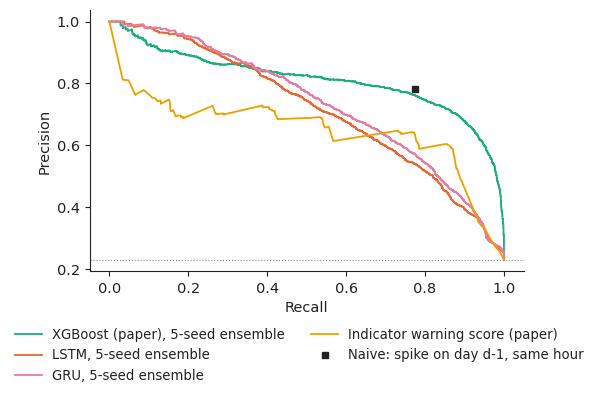

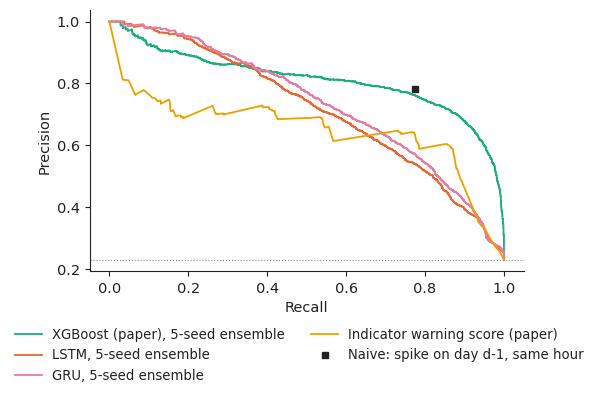

In [11]:
# Is the LSTM ensemble better than XGBoost? Block bootstrap over test DAYS (1,000 resamples, seed 0) of the difference in PR-AUC and F1.
cd = y[common].index.get_level_values("day"); ud = cd.unique()
pos = {d_: np.where(cd == d_)[0] for d_ in ud}
yy, pl, px = y[common].values, ens["lstm"][common].values, xgb_ens[common].values
al_l, al_x = pl > cut["lstm"], px > cut["xgb"]
rng = np.random.default_rng(0); dpr, df1 = [], []
for _ in range(1000):
    ii = np.concatenate([pos[d_] for d_ in rng.choice(ud, len(ud))])
    dpr.append(average_precision_score(yy[ii], pl[ii]) - average_precision_score(yy[ii], px[ii]))
    df1.append(f1_score(yy[ii], al_l[ii]) - f1_score(yy[ii], al_x[ii]))
dpr, df1 = np.array(dpr), np.array(df1)
boot = {"dPR": dpr.mean(), "dPRlo": np.percentile(dpr, 2.5), "dPRhi": np.percentile(dpr, 97.5), "pPR": (dpr <= 0).mean(),
        "dFone": df1.mean(), "dFlo": np.percentile(df1, 2.5), "dFhi": np.percentile(df1, 97.5)}
print({k: round(v, 3) for k, v in boot.items()})
names = {"xgb": ("XGBoost (paper), 5-seed ensemble", "XGBoost (lucrarea), ansamblu de 5 rulări"),
         "lstm": ("LSTM, 5-seed ensemble", "LSTM, ansamblu de 5 rulări"), "gru": ("GRU, 5-seed ensemble", "GRU, ansamblu de 5 rulări"),
         "ind": ("Indicator warning score (paper)", "Scorul de avertizare cu indicatori (lucrarea)"),
         "naive": ("Naive: spike on day d-1, same hour", "Naiv: vîrf în ziua d-1, la aceeași oră")}
t = res[["Precision", "Recall", "F1", "sdF1", "PR-AUC", "sdPR", "AUC"]].copy(); t.index = [names[i] for i in t.index]
cu.write_table(t, "warning", header=[("Early-warning rule (test period)", "Regula de avertizare (perioada de test)"), ("Precision", "Precizia"),
               ("Recall", "Sensibilitatea"), ("F1", "F1"), ("s.d.", "a.s."), ("PR-AUC", "PR-AUC"), ("s.d.", "a.s."), ("AUC", "AUC")], digits=3,
               best={"Precision": "max", "Recall": "max", "F1": "max", "PR-AUC": "max", "AUC": "max"})
def fig_pr(lang):
    fig, ax = plt.subplots(figsize=(5.6, 3.4))
    for k, col, sc in [("xgb", cu.PAL["HU"], xgb_ens), ("lstm", cu.PAL["DE_LU"], ens["lstm"]), ("gru", cu.PAL["c5"], ens["gru"]), ("ind", cu.PAL["BG"], W)]:
        pp, rr, _ = precision_recall_curve(y[common], sc[common])
        ax.plot(rr, pp, color=col, lw=1.3, label=cu.T(lang, *names[k]))
    ax.plot(res.loc["naive", "Recall"], res.loc["naive", "Precision"], "s", color=cu.INK, ms=5, label=cu.T(lang, *names["naive"]))
    ax.axhline(y[common].mean(), color=cu.MUTED, ls=":", lw=0.8)
    ax.set_xlabel(cu.T(lang, "Recall", "Sensibilitatea")); ax.set_ylabel(cu.T(lang, "Precision", "Precizia"))
    cu.comma_axis(ax, lang, "x"); cu.comma_axis(ax, lang, "y")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_pr, "f2_pr_curves")

## 4. Which hours of the past drive the network's alert? Integrated gradients over time

share of attribution: day d-1 91.8 %, day d-2 6.6 %, days d-14..d-3 1.7 % (day d-7: 0.01 %)
most attributed hours of day d-1: [23 20 22 21]
price         36.099998
solar         10.100000
gas            8.500000
load           7.500000
hydro          6.200000
resid_load     5.800000
net_import     4.600000
wind           3.800000
dtype: float32


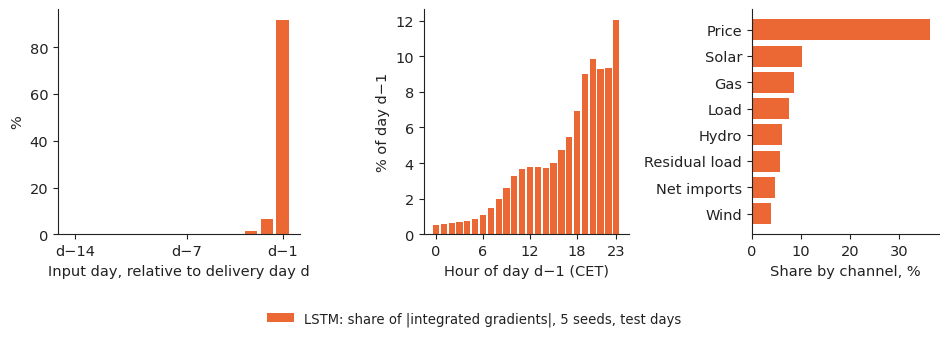

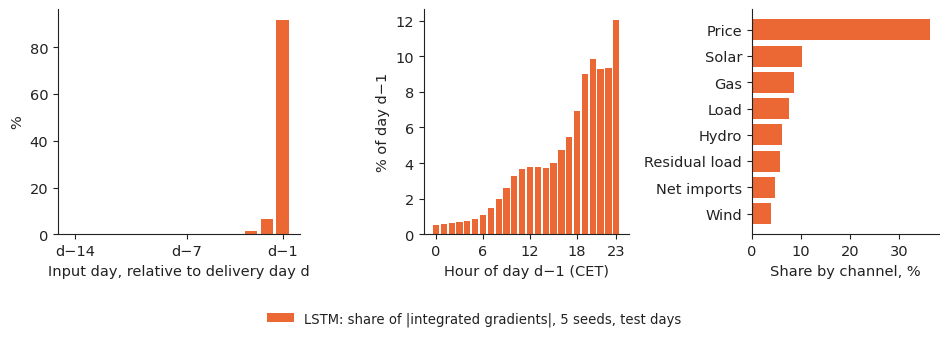

In [12]:
# Integrated gradients (Sundararajan et al., 2017): IG_j = (x_j - x'_j) * mean over alpha in (0,1] of dF/dx_j at x' + alpha (x - x'),
# with baseline x' = 0 (the training mean of every standardised channel) and F = sum of the 24 output logits (tomorrow's overall spike score).
# 32 steps (Riemann sum); test days; the 5 LSTM seeds; we keep |IG| by time step and channel.
def integrated_gradients(net, xs, ss, steps=32):
    tot = torch.zeros_like(xs)
    for a in (np.arange(steps) + 1) / steps:
        xa = (a * xs).requires_grad_(True)
        net(xa, ss).sum().backward()
        tot += xa.grad.detach()
    return (xs * tot / steps).numpy()
xt, st = torch.from_numpy(Xseq[seg["test"]]), torch.from_numpy(S[seg["test"]])
IG = np.mean([np.abs(integrated_gradients(nets[("lstm", s)], xt, st)) for s in SEEDS], axis=0)   # (days, 336, channels)
by_lag = IG.sum(axis=2).mean(axis=0); by_lag = by_lag / by_lag.sum() * 100       # % of total attribution per input hour
hours_back = np.arange(LB * 24, 0, -1)                                            # 336 ... 1 hours before the start of day d
by_ch = IG.mean(axis=(0, 1))[:len(CH)]; by_ch = pd.Series(by_ch / IG.mean(axis=(0, 1)).sum() * 100, index=CH)
by_day = by_lag.reshape(LB, 24).sum(axis=1)                                       # day d-14 ... d-1
last_day, day2, older = by_day[-1], by_day[-2], by_day[:-2].sum()
week_ago = by_day[-7]
print("share of attribution: day d-1 %.1f %%, day d-2 %.1f %%, days d-14..d-3 %.1f %% (day d-7: %.2f %%)" % (last_day, day2, older, week_ago))
within = by_lag[-24:] / by_lag[-24:].sum() * 100                                   # inside day d-1, by hour of day
print("most attributed hours of day d-1:", np.argsort(within)[::-1][:4])
print(by_ch.sort_values(ascending=False).round(1))
CHN = {"price": ("Price", "Preț"), "load": ("Load", "Consum"), "solar": ("Solar", "Solar"), "wind": ("Wind", "Eolian"),
       "resid_load": ("Residual load", "Consum rezidual"), "hydro": ("Hydro", "Hidro"), "gas": ("Gas", "Gaze"), "net_import": ("Net imports", "Importuri nete")}
def fig_ig(lang):
    fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.0), gridspec_kw={"width_ratios": [1.3, 1.1, 1]})
    a = axes[0]
    a.bar(np.arange(-LB, 0), by_day, width=0.8, color=cu.PAL["DE_LU"], label=cu.T(lang, "LSTM: share of |integrated gradients|, 5 seeds, test days", "LSTM: ponderea |gradienților integrați|, 5 rulări, zilele de test"))
    a.set_xlabel(cu.T(lang, "Input day, relative to delivery day d", "Ziua de intrare, față de ziua de livrare d"))
    a.set_ylabel("%"); a.set_xticks([-14, -7, -1]); a.set_xticklabels(["d−14", "d−7", "d−1"])
    cu.comma_axis(a, lang, "y")
    b = axes[1]
    b.bar(np.arange(24), within, width=0.8, color=cu.PAL["DE_LU"])
    b.set_xlabel(cu.T(lang, "Hour of day d−1 (CET)", "Ora din ziua d−1 (CET)")); b.set_ylabel(cu.T(lang, "% of day d−1", "% din ziua d−1"))
    b.set_xticks([0, 6, 12, 18, 23]); cu.comma_axis(b, lang, "y")
    c = axes[2]
    o = by_ch.sort_values()
    c.barh([cu.T(lang, *CHN[k]) for k in o.index], o.values, color=cu.PAL["DE_LU"])
    c.set_xlabel(cu.T(lang, "Share by channel, %", "Ponderea pe canale, %"))
    cu.comma_axis(c, lang, "x")
    fig.tight_layout()
    cu.legend_bottom(fig, ncol=1)
    return fig
cu.save_both(fig_ig, "f3_time_attribution", headline=True)

## 5. From a probability to a decision

L = 150.8 EUR/MWh, C/L = 0.199; value at C/L (thousand EUR per MW): {'lstm': np.float64(127.3), 'xgb': np.float64(159.5), 'gru': np.float64(129.5)}; naive rule: 157.6


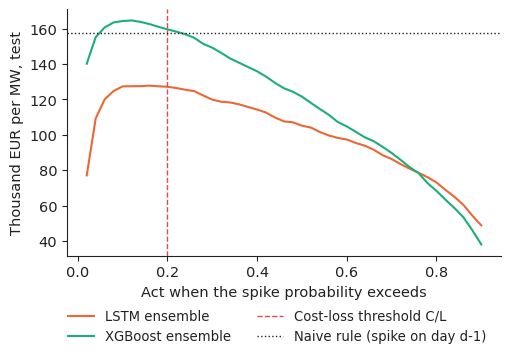

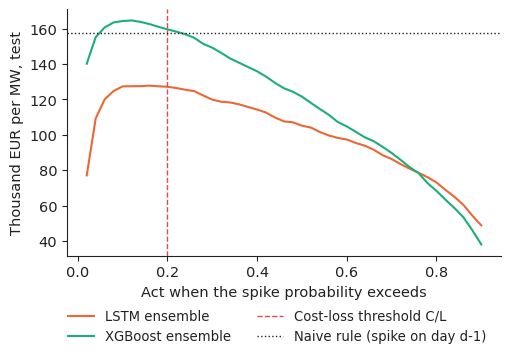

In [13]:
# Cost-loss rule: acting (shifting 1 MWh of flexible load out of the hour) costs C; a spike we did not act on costs L.
# Act when the probability exceeds C / L. C = 30 EUR/MWh (stated assumption); L = mean spike price minus mean non-spike price in TRAINING.
C_ACT = 30.0
LOSS = H.loc[itr & (H.spike == 1), "price"].mean() - H.loc[itr & (H.spike == 0), "price"].mean()
pc = C_ACT / LOSS
prices_te = H.price[common]
def value(score, cut_):
    act = score[common] > cut_
    return ((prices_te - prices_te.mean()) * act).sum() - C_ACT * act.sum()       # money saved by not buying in flagged hours, minus action cost
cuts = np.linspace(0.02, 0.9, 45)
vals = {k: np.array([value(sc, c) for c in cuts]) / 1000 for k, sc in [("lstm", ens["lstm"]), ("xgb", xgb_ens)]}
val_pc = {k: value(sc, pc) / 1000 for k, sc in [("lstm", ens["lstm"]), ("xgb", xgb_ens), ("gru", ens["gru"])]}
val_naive = value(X.price_lag24, thr) / 1000
print("L = %.1f EUR/MWh, C/L = %.3f; value at C/L (thousand EUR per MW): %s; naive rule: %.1f" % (LOSS, pc, {k: round(v, 1) for k, v in val_pc.items()}, val_naive))
def fig_decision(lang):
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    ax.plot(cuts, vals["lstm"], color=cu.PAL["DE_LU"], lw=1.5, label=cu.T(lang, "LSTM ensemble", "Ansamblul LSTM"))
    ax.plot(cuts, vals["xgb"], color=cu.PAL["HU"], lw=1.5, label=cu.T(lang, "XGBoost ensemble", "Ansamblul XGBoost"))
    ax.axvline(pc, color=cu.PAL["c8"], ls="--", lw=1, label=cu.T(lang, "Cost-loss threshold C/L", "Pragul cost-pierdere C/L"))
    ax.axhline(val_naive, color=cu.INK, ls=":", lw=1, label=cu.T(lang, "Naive rule (spike on day d-1)", "Regula naivă (vîrf în ziua d-1)"))
    ax.set_xlabel(cu.T(lang, "Act when the spike probability exceeds", "Reacționăm cînd probabilitatea vîrfului depășește"))
    ax.set_ylabel(cu.T(lang, "Thousand EUR per MW, test", "Mii EUR pe MW, perioada de test"))
    cu.comma_axis(ax, lang, "x"); cu.comma_axis(ax, lang, "y")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_decision, "f5_decision")

In [14]:
r = res
lr, gr = net_runs.query("model == 'lstm'"), net_runs.query("model == 'gru'")
cu.write_numbers({
    "thr": thr, "spikeTrain": 100 * H.loc[itr, "spike"].mean(), "spikeVal": 100 * H.loc[iva, "spike"].mean(), "spikeTest": 100 * H.loc[ite, "spike"].mean(),
    "nTest": int(common.sum()), "nTestDays": len(seg["test"]), "nTrainDays": len(seg["train"]),
    "eveTrain": share_h.loc[18:21, "train"].mean(), "eveTest": share_h.loc[18:21, "test"].mean(),
    "WStar": W_star, "top": NM.get(imp.index[0], (imp.index[0],) * 2), "second": NM.get(imp.index[1], (imp.index[1],) * 2), "third": NM.get(imp.index[2], (imp.index[2],) * 2),
    "xPrec": r.loc["xgb", "Precision"], "xRec": r.loc["xgb", "Recall"], "xFone": r.loc["xgb", "F1"], "xPR": r.loc["xgb", "PR-AUC"], "xAUC": r.loc["xgb", "AUC"],
    "lPrec": r.loc["lstm", "Precision"], "lRec": r.loc["lstm", "Recall"], "lFone": r.loc["lstm", "F1"], "lPR": r.loc["lstm", "PR-AUC"], "lAUC": r.loc["lstm", "AUC"],
    "gFone": r.loc["gru", "F1"], "gPR": r.loc["gru", "PR-AUC"], "gAUC": r.loc["gru", "AUC"],
    "wFone": r.loc["ind", "F1"], "wPR": r.loc["ind", "PR-AUC"], "wRec": r.loc["ind", "Recall"], "nFone": r.loc["naive", "F1"], "nRec": r.loc["naive", "Recall"], "nPrec": r.loc["naive", "Precision"],
    "lsdF": r.loc["lstm", "sdF1"], "xsdF": r.loc["xgb", "sdF1"], "lsdPR": r.loc["lstm", "sdPR"],
    "lPRmin": lr["PR-AUC"].min(), "lPRmax": lr["PR-AUC"].max(), "lEpochs": lr.epochs.mean(), "gPRmin": gr["PR-AUC"].min(), "gPRmax": gr["PR-AUC"].max(), "pAUC": r.loc["naive", "PR-AUC"],
    "valG": val_pc["gru"], "trainSec": train_sec,
    "dPR": boot["dPR"], "dPRlo": boot["dPRlo"], "dPRhi": boot["dPRhi"], "dFone": boot["dFone"], "dFlo": boot["dFlo"], "dFhi": boot["dFhi"],
    "igLast": last_day, "igDtwo": day2, "igOld": older, "igWeek": week_ago, "igPrice": by_ch["price"], "igEve": within[17:22].sum(),
    "igTop": CHN[by_ch.idxmax()], "igSecond": CHN[by_ch.sort_values().index[-2]],
    "loss": LOSS, "pc": pc, "valL": val_pc["lstm"], "valX": val_pc["xgb"], "valN": val_naive,
}, digits={"thr": 2, "spikeTrain": 1, "spikeVal": 1, "spikeTest": 1, "eveTrain": 1, "eveTest": 1, "WStar": 3,
           **{k: 3 for k in ["xPrec", "xRec", "xFone", "xPR", "xAUC", "lPrec", "lRec", "lFone", "lPR", "lAUC", "gFone", "gPR", "gAUC", "wFone", "wPR", "wRec",
                             "nFone", "nRec", "nPrec", "lsdF", "xsdF", "lsdPR", "lPRmin", "lPRmax", "gPRmin", "gPRmax", "pAUC", "dPR", "dPRlo", "dPRhi", "dFone", "dFlo", "dFhi", "pc"]},
           "lEpochs": 1, "igLast": 1, "igDtwo": 1, "igOld": 1, "igWeek": 2, "igPrice": 1, "igEve": 1, "loss": 1, "valL": 1, "valX": 1, "valN": 1, "valG": 1, "trainSec": 0})
print(open("numbers_en.tex", encoding="utf-8").read())

% generated by the case notebook -- do not edit
\newcommand{\Nthr}{163.43}
\newcommand{\NspikeTrain}{10.0}
\newcommand{\NspikeVal}{14.2}
\newcommand{\NspikeTest}{23.1}
\newcommand{\NnTest}{11,710}
\newcommand{\NnTestDays}{488}
\newcommand{\NnTrainDays}{731}
\newcommand{\NeveTrain}{30.6}
\newcommand{\NeveTest}{53.4}
\newcommand{\NWStar}{0.550}
\newcommand{\Ntop}{Price, same hour of day d-1}
\newcommand{\Nsecond}{Day of week}
\newcommand{\Nthird}{Price, same hour one week earlier}
\newcommand{\NxPrec}{0.821}
\newcommand{\NxRec}{0.524}
\newcommand{\NxFone}{0.640}
\newcommand{\NxPR}{0.811}
\newcommand{\NxAUC}{0.946}
\newcommand{\NlPrec}{0.725}
\newcommand{\NlRec}{0.522}
\newcommand{\NlFone}{0.607}
\newcommand{\NlPR}{0.718}
\newcommand{\NlAUC}{0.865}
\newcommand{\NgFone}{0.625}
\newcommand{\NgPR}{0.736}
\newcommand{\NgAUC}{0.875}
\newcommand{\NwFone}{0.521}
\newcommand{\NwPR}{0.649}
\newcommand{\NwRec}{0.409}
\newcommand{\NnFone}{0.779}
\newcommand{\NnRec}{0.776}
\newcommand{\NnPrec}{0.782}

In [15]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F_ = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Explainable spike early warning} (Andrei, Pele, Cramer, Amza \\& Diaconu, 2026, PICBE): previous price and residual load drive spikes (SHAP, Table~5); warning system recall 0.722, F1 0.569 (Table~7).",
          "\\textbf{Avertizarea explicabilă a vîrfurilor de preț} (Andrei, Pele, Cramer, Amza și Diaconu, 2026, PICBE): prețul anterior și consumul rezidual determină vîrfurile (SHAP, Tabelul~5); sensibilitatea sistemului este 0,722, iar F1 este 0,569 (Tabelul~7)."),
        t(f"Our replication (test July 2025 -- October 2026, gate-closure information): XGBoost PR-AUC {F_(r.loc['xgb', 'PR-AUC'])}, LSTM on 14 days of hourly history {F_(r.loc['lstm', 'PR-AUC'])} (5 seeds each).",
          f"Replicarea noastră (test iulie 2025 -- octombrie 2026, informația de la închiderea porții): XGBoost PR-AUC {F_(r.loc['xgb', 'PR-AUC'])}, LSTM pe 14 zile de istoric orar {F_(r.loc['lstm', 'PR-AUC'])} (cîte 5 rulări)."),
        t(f"Integrated gradients: {F_(last_day, 0)}\\,\\% of the LSTM's attribution falls on the last known day, {F_(by_ch['price'], 0)}\\,\\% on the price channel.",
          f"Gradienții integrați: {F_(last_day, 0)}\\,\\% din atribuirea rețelei LSTM revine ultimei zile cunoscute, iar {F_(by_ch['price'], 0)}\\,\\% canalului de preț."),
        t("Decision: act when the spike probability exceeds $C/L$, set from your own costs.",
          "Decizia: reacționați atunci cînd probabilitatea unui vîrf depășește $C/L$, raport stabilit din propriile costuri."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Explainable spike early warning} (Andrei, Pele, Cramer, Amza \& Diaconu, 2026, PICBE): previous price and residual load drive spikes (SHAP, Table~5); warning system recall 0.722, F1 0.569 (Table~7).
  \item Our replication (test July 2025 -- October 2026, gate-closure information): XGBoost PR-AUC 0.81, LSTM on 14 days of hourly history 0.72 (5 seeds each).
  \item Integrated gradients: 92\,\% of the LSTM's attribution falls on the last known day, 36\,\% on the price channel.
  \item Decision: act when the spike probability exceeds $C/L$, set from your own costs.
\end{itemize}



## Your turn
1. Shorten the input window from 14 to 3 days (`LB = 3`). Does the PR-AUC of the LSTM change? What does that say about long memory in spike risk?
2. Remove the price channel from the network's input. How much of the performance is left, and which channel takes over in the attributions?
3. Re-estimate on the paper's window only (March-September 2024). Do you get the paper's ranking of drivers (previous price, residual load)?
4. Change the action cost C from 30 to 100 EUR/MWh. How does the cost-loss threshold move, and which model gains more value?